# Figure 5a: TCN response rate versus maximum PCN capacity

In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb

OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs("Figure5_outputs")
PCN_CAPACITY_GRID = (np.array([20, 40, 60, 80, 100], dtype=int)
                     if RUN_MODE == "quick" else np.arange(20, 101, 5, dtype=int))
CONDITIONS = ("transposition on", "transposition off")


In [2]:
rows=[]
for max_pcn in PCN_CAPACITY_GRID:
    configs={c.condition:c for c in standard_configurations(int(max_pcn))}
    for condition in CONDITIONS:
        rows.append(evaluate_configuration(int(max_pcn), configs[condition]))
results=pd.DataFrame(rows)

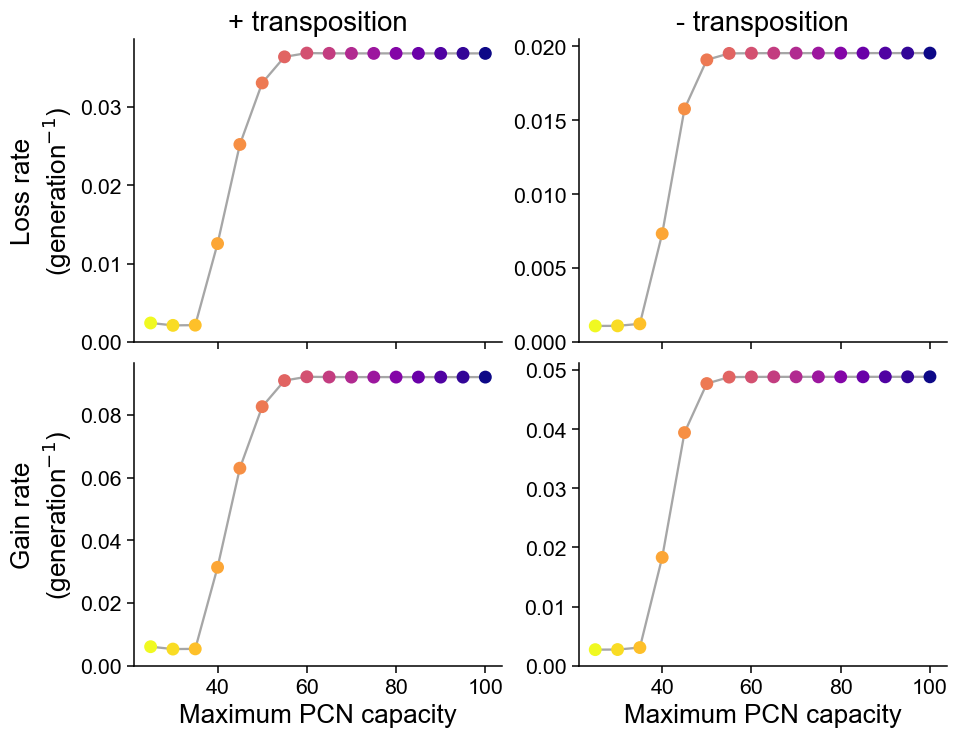

In [3]:
plt.rcParams.update(PLOT_STYLE)
LARGE_FONT_STYLE = {
    "font.size": 14, "axes.labelsize": 17, "axes.titlesize": 18,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 15,
    "axes.linewidth": 1.0, "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5,
}
plt.rcParams.update(LARGE_FONT_STYLE)
PANEL_FONT = 18
fig, axes = plt.subplots(2, 2, figsize=(8.6, 6.6), sharex='col', constrained_layout=True)
for col, condition in enumerate(CONDITIONS):
    d=results[(results.condition==condition) & results.response_valid].sort_values("maximum_PCN")
    for row, metric, ylabel in ((0,"loss_rate","Loss rate\n(generation$^{-1}$)"),
                                (1,"gain_rate","Gain rate\n(generation$^{-1}$)")):
        ax=axes[row,col]
        ax.plot(d.maximum_PCN, d[metric], color="0.65", lw=1.5)
        ax.scatter(d.maximum_PCN, d[metric], c=d.maximum_PCN, cmap="plasma_r", s=55, zorder=3)
        ax.set_ylim(bottom=0)
        if col==0: ax.set_ylabel(ylabel)
        if row==1: ax.set_xlabel("Maximum PCN capacity")
    axes[0,col].set_title("+ transposition" if condition=="transposition on" else "- transposition")
fig.align_ylabels(axes[:,0])
save_figure(fig, "Figure5a_capacity_response", FIGURE_DIR)
plt.show()

export_table(results, "Figure5a_source_data.csv", SOURCE_DIR)
export_table(core_metadata("Figure 5a"), "Figure5a_run_metadata.csv", SOURCE_DIR)
